## Preprocessing Validation Citra Rontgen Osteoarthritis menggunakan CLAHE, Gaussian, Edge Detection, Morphological, Grayscale

#### Import Library untuk Preprocessing

In [13]:
import cv2
import os
import matplotlib.pyplot as plt

#### Mendefinisikan Path Input dan Output

In [15]:
# Folder input
input_folder = r'C:\Users\Asus\PENELITIAN_RINI_VAMULIA_OA_CNN\DataSetOA_6200\ValOA_620'

# Folder output untuk setiap tahap preprocessing
output_base = r'C:\Users\Asus\PENELITIAN_RINI_VAMULIA_OA_CNN\Processed_ValOA'
output_folders = {
    "CLAHE": os.path.join(output_base, "CLAHE"),
    "Gaussian": os.path.join(output_base, "Gaussian"),
    "EdgeDetection": os.path.join(output_base, "EdgeDetection"),
    "Morphological": os.path.join(output_base, "Morphological"),
    "Final": os.path.join(output_base, "Final")  # Folder untuk gabungan grayscale asli + morphological
}

#### Membuat Folder Output Otomatis

In [17]:
# Fungsi untuk membuat folder jika belum ada
def create_folders():
    for folder in output_folders.values():
        os.makedirs(folder, exist_ok=True)
        for grade in range(5):
            grade_folder = os.path.join(folder, f"Grade{grade}")
            os.makedirs(grade_folder, exist_ok=True)

#### Mendefinisikan Fungsi-fungsi Preprocessing

In [19]:
# Fungsi untuk menampilkan gambar per tahap
def display_images(images, titles, grade, img_count):
    plt.figure(figsize=(15, 5))
    plt.suptitle(f"Grade {grade} - Image {img_count + 1}")
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(image, cmap='gray')
        plt.title(title)
        plt.axis('off')
    plt.show()

# Fungsi CLAHE preprocessing
def preprocess_clahe(image):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(image)

# Fungsi Gaussian Filtering
def gaussian_filter(image):
    return cv2.GaussianBlur(image, (3, 3), 0)

# Fungsi Edge Detection (Canny)
def edge_detection(image):
    return cv2.Canny(image, 50, 150)

# Fungsi Morphological Operation
def morphological_operation(image):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    return cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

# Fungsi untuk menggabungkan grayscale asli dengan hasil morphological
def combine_grayscale_morph(original, morph):
    combined = cv2.addWeighted(original, 0.5, morph, 0.5, 0)  # Gabungan dengan rasio 50:50
    return combined

#### Mendefinisikan Fungsi Utama Preprocessing

In [21]:
# Fungsi utama untuk menjalankan semua tahap preprocessing
def process_images():
    create_folders()

    for grade_folder in os.listdir(input_folder):
        grade_path = os.path.join(input_folder, grade_folder)
        if os.path.isdir(grade_path):
            print(f"Processing Grade: {grade_folder}")

            count = 0
            for filename in os.listdir(grade_path):
                if filename.endswith(('.jpg', '.png')):
                    img_path = os.path.join(grade_path, filename)
                    image = cv2.imread(img_path, 0)

                    # CLAHE
                    clahe_image = preprocess_clahe(image)
                    clahe_output_path = os.path.join(output_folders["CLAHE"], grade_folder, f"clahe_{filename}")
                    cv2.imwrite(clahe_output_path, clahe_image)

                    # Gaussian Filtering
                    gaussian_image = gaussian_filter(clahe_image)
                    gaussian_output_path = os.path.join(output_folders["Gaussian"], grade_folder, f"gaussian_{filename}")
                    cv2.imwrite(gaussian_output_path, gaussian_image)

                    # Edge Detection
                    edge_image = edge_detection(gaussian_image)
                    edge_output_path = os.path.join(output_folders["EdgeDetection"], grade_folder, f"edge_{filename}")
                    cv2.imwrite(edge_output_path, edge_image)

                    # Morphological Operation
                    morph_image = morphological_operation(edge_image)
                    morph_output_path = os.path.join(output_folders["Morphological"], grade_folder, f"morph_{filename}")
                    cv2.imwrite(morph_output_path, morph_image)

                    # Gabungkan grayscale asli dengan morphological
                    final_image = combine_grayscale_morph(image, morph_image)
                    final_output_path = os.path.join(output_folders["Final"], grade_folder, f"final_{filename}")
                    cv2.imwrite(final_output_path, final_image)

                    # Tampilkan gambar 2 per grade
                    if count < 2:
                        display_images(
                            [image, clahe_image, gaussian_image, edge_image, morph_image, final_image],
                            ["Original", "CLAHE", "Gaussian", "Edge Detection", "Morphological", "Final"],
                            grade_folder, count
                        )
                        count += 1

            print(f"Processing for {grade_folder} completed!\n")

#### Menjalankan Preprocessing

Processing Grade: .ipynb_checkpoints
Processing for .ipynb_checkpoints completed!

Processing Grade: Grade0


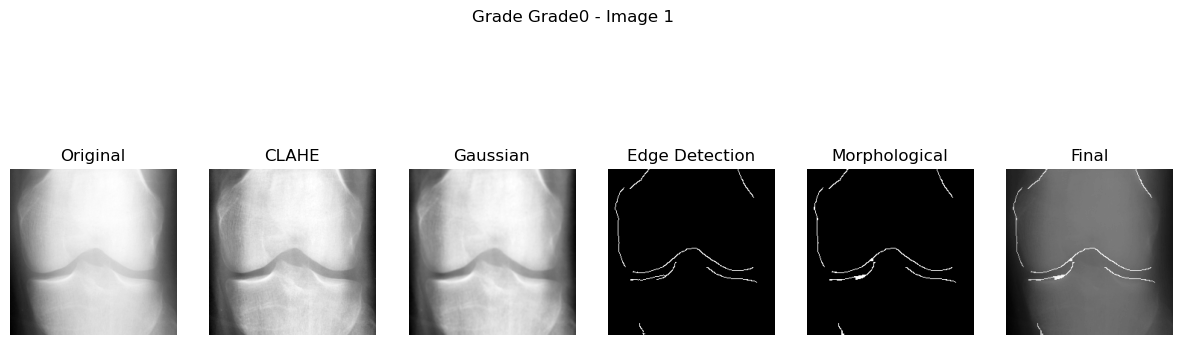

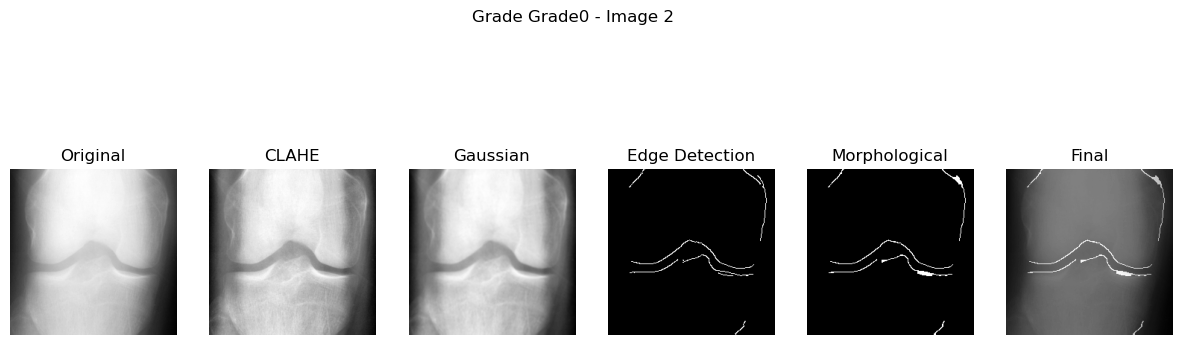

Processing for Grade0 completed!

Processing Grade: Grade1


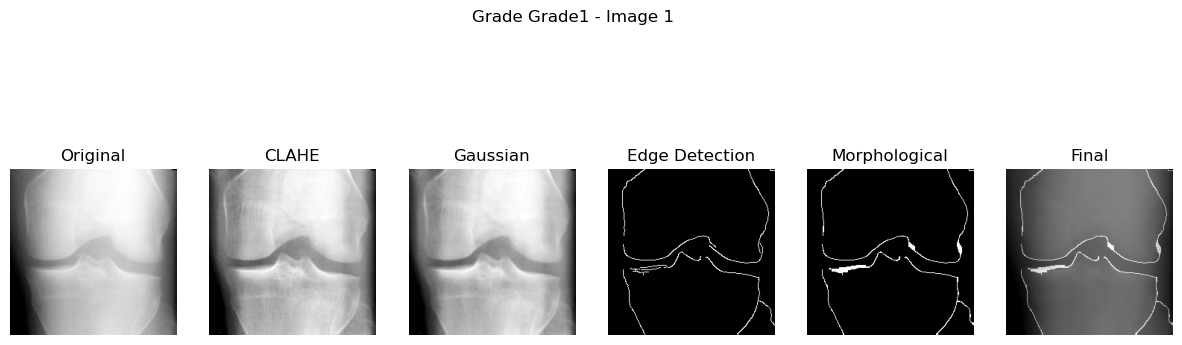

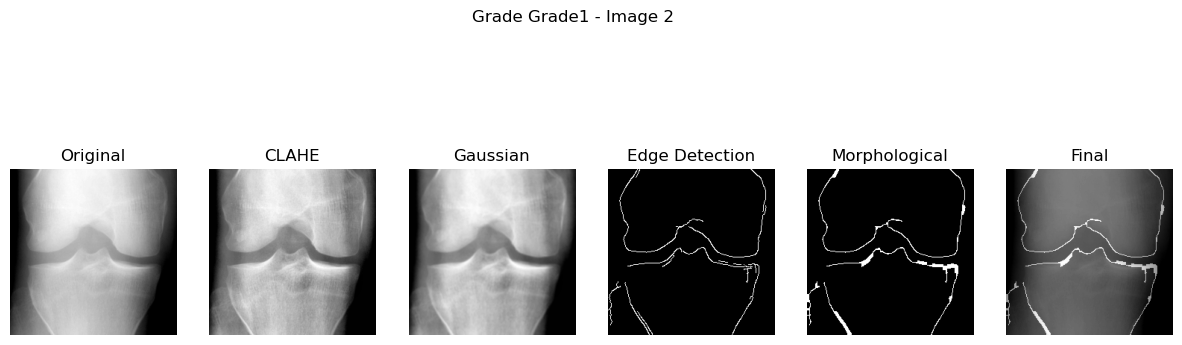

Processing for Grade1 completed!

Processing Grade: Grade2


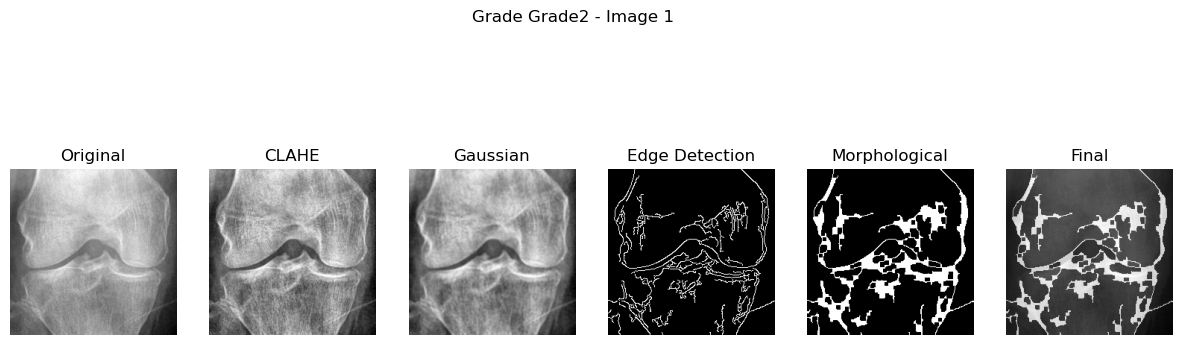

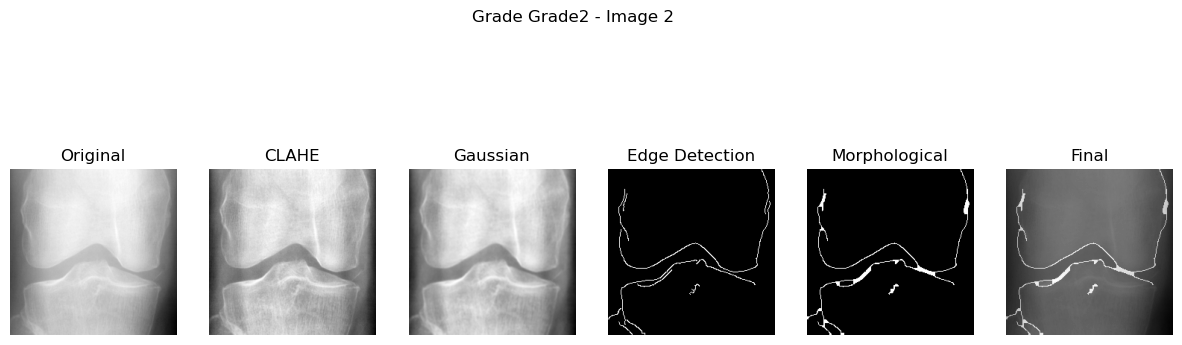

Processing for Grade2 completed!

Processing Grade: Grade3


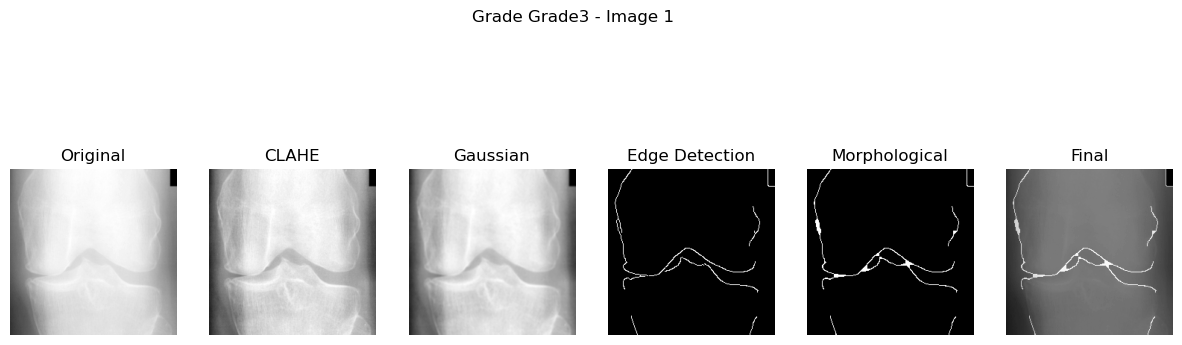

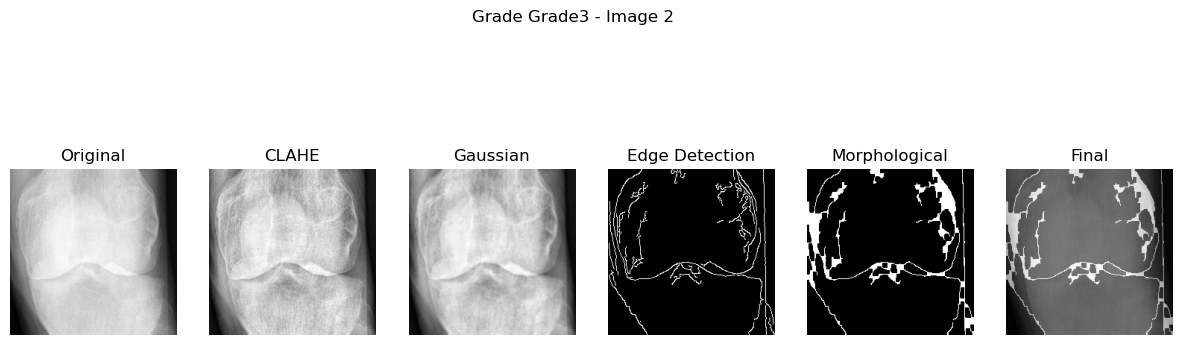

Processing for Grade3 completed!

Processing Grade: Grade4


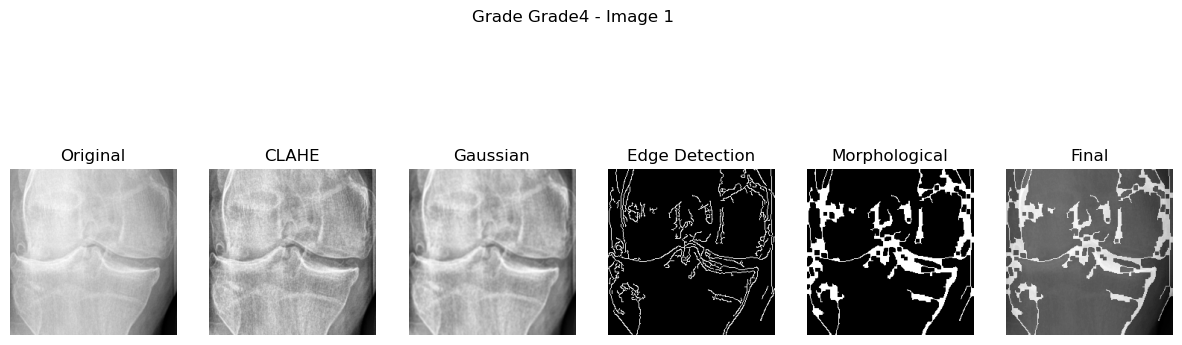

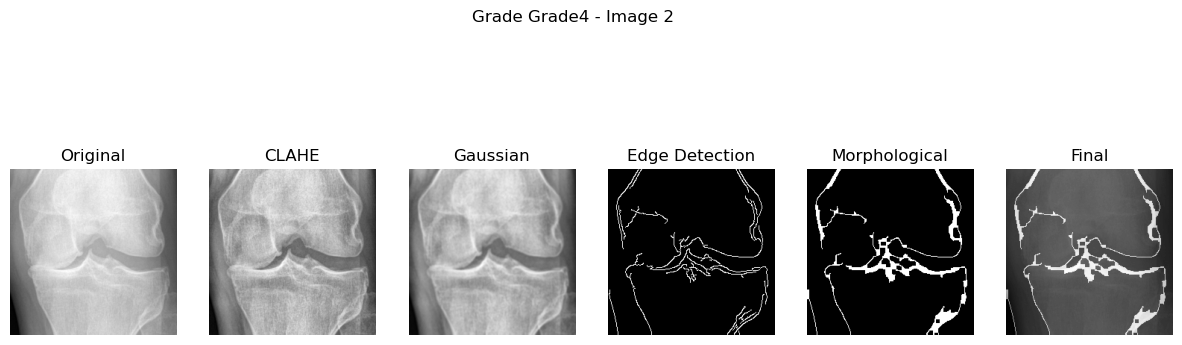

Processing for Grade4 completed!

Preprocessing complete for all grades!


In [23]:
process_images()
print("Preprocessing complete for all grades!")